# EDA A4 – Czy biznes rośnie?

Pytanie biznesowe: **jak zmieniają się zamówienia i przychód w czasie – trend, sezonowość, statusy?**

Z A2 wiemy, że liczba nowych użytkowników jest stała (~1 040 miesięcznie od 2019 r.).
**Jeśli przychód mimo to rośnie, skąd bierze się wzrost?** Sprawdzamy rolę klientów powracających.

Zasady z A1:
* daty bierzemy z **`orders.created_at`** (`order_items.created_at` jest niewiarygodne),
* przychód = Complete + Shipped,
* bieżący, niepełny miesiąc pomijamy w trendach.

## Wczytanie danych

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter

from bq_utils import read_bq
from viz_style import apply_style, legend_outside, COLORS, MONTHS_PL

apply_style()

REVENUE_STATUSES = ["Complete", "Shipped"]

# Axis formatter: 125000 -> "125 tys."
thousands = FuncFormatter(lambda v, _: f"{v / 1000:,.0f} tys.".replace(",", " "))

In [2]:
# Orders

orders = read_bq("orders", usecols=["order_id", "user_id", "status", "created_at", "num_of_item"],
                 dtype={"order_id": "Int32", "user_id": "Int32", "status": "category",
                        "num_of_item": "Int8"})

orders.head()

Zapytanie przetworzy: 5.26 MB


,order_id,user_id,status,created_at,num_of_item
0,52,37,Cancelled,2024-07-08 20:05:34+00:00,1
1,55,41,Cancelled,2026-09-02 11:34:36+00:00,1
2,68,55,Cancelled,2024-11-03 21:25:40+00:00,1
3,90,68,Cancelled,2025-09-30 19:33:00+00:00,1
4,97,73,Cancelled,2024-11-01 23:59:38+00:00,1


In [3]:
# Order items – only order value

order_items = read_bq("order_items", usecols=["order_id", "sale_price"],
                      dtype={"order_id": "Int32"})

order_items.head()

Zapytanie przetworzy: 2.89 MB


,order_id,sale_price
0,2526,0.02
1,18153,0.02
2,47981,0.02
3,84256,0.02
4,348,0.02


In [4]:
# Users – signup date, to compare with the first order

users = read_bq("users", usecols=["id", "created_at"], dtype={"id": "Int32"})

users.head()

Zapytanie przetworzy: 1.60 MB


,id,created_at
0,81146,2025-05-05 15:58:00+00:00
1,56556,2026-01-30 03:19:00+00:00
2,2792,2026-10-27 06:00:53.805757+00:00
3,18073,2022-10-31 12:32:00+00:00
4,35509,2024-02-27 17:48:00+00:00


In [5]:
# Data as of

checked_at = pd.Timestamp.now(tz="UTC")
current_month = checked_at.tz_localize(None).to_period("M")

print(f"Sprawdzono: {checked_at:%Y-%m-%d %H:%M} UTC, bieżący (pomijany) miesiąc: {current_month}")

Sprawdzono: 2026-10-29 09:10 UTC, bieżący (pomijany) miesiąc: 2026-10


## Tabela zamówień do analizy

Jeden wiersz = jedno zamówienie, z dodatkowymi kolumnami:
* `order_value` – suma `sale_price` pozycji,
* `revenue` – wartość zamówienia, jeśli liczy się do przychodu (Complete + Shipped), w przeciwnym razie 0,
* `month`, `year` – z `orders.created_at`,
* `order_rank` – które to zamówienie klienta (1 = pierwsze) → `customer_type`: new / returning.

`order_rank` liczymy na **wszystkich** zamówieniach, zanim odrzucimy bieżący miesiąc.

In [6]:
# Orders enriched with value, revenue, month and customer type

order_value = order_items.groupby("order_id")["sale_price"].sum().rename("order_value")

orders_v = (orders
            .merge(order_value, left_on="order_id", right_index=True, how="left",
                   validate="one_to_one")
            .fillna({"order_value": 0})
            .assign(is_revenue=lambda x: x["status"].isin(REVENUE_STATUSES),
                    revenue=lambda x: x["order_value"].where(x["is_revenue"], 0),
                    month=lambda x: x["created_at"].dt.tz_localize(None).dt.to_period("M"),
                    order_rank=lambda x: x.sort_values("created_at").groupby("user_id").cumcount() + 1,
                    customer_type=lambda x: np.where(x["order_rank"] == 1, "new", "returning"))
            .assign(year=lambda x: x["month"].dt.year)
            .loc[lambda x: x["month"] < current_month])

print(f"Zamówienia: {len(orders):,} -> do analizy (pełne miesiące): {len(orders_v):,}")
print(f"Przychód: {orders_v['revenue'].sum():,.0f}")

orders_v.head()

Zamówienia: 124,452 -> do analizy (pełne miesiące): 114,830
Przychód: 5,483,088


,order_id,user_id,status,created_at,num_of_item,order_value,is_revenue,revenue,month,order_rank,customer_type,year
0,52,37,Cancelled,2024-07-08 20:05:34+00:00,1,29.99,False,0.0,2024-07,1,new,2024
1,55,41,Cancelled,2026-09-02 11:34:36+00:00,1,25.00,False,0.0,2026-09,1,new,2026
2,68,55,Cancelled,2024-11-03 21:25:40+00:00,1,40.00,False,0.0,2024-11,2,returning,2024
3,90,68,Cancelled,2025-09-30 19:33:00+00:00,1,24.99,False,0.0,2025-09,2,returning,2025
4,97,73,Cancelled,2024-11-01 23:59:38+00:00,1,20.99,False,0.0,2024-11,2,returning,2024


## 1. Trend miesięczny

* Liczba zamówień, zamówień liczonych do przychodu, przychód, aktywni klienci, AOV – miesiąc po miesiącu.

In [7]:
# Monthly KPIs

monthly = (orders_v
           .groupby("month")
           .agg(orders=("order_id", "count"),
                revenue_orders=("is_revenue", "sum"),
                revenue=("revenue", "sum"),
                active_customers=("user_id", "nunique"))
           .assign(aov=lambda x: x["revenue"] / x["revenue_orders"]))

monthly.tail(13).round(1)

,orders,revenue_orders,revenue,active_customers,aov
month,,,,,
2025-09,2549,1382,118786.6,2509,86.0
2025-10,2648,1510,127312.8,2597,84.3
2025-11,2660,1481,119678.1,2614,80.8
2025-12,2984,1664,141517.0,2925,85.0
2026-01,3059,1674,146200.6,2991,87.3
2026-02,2903,1585,133089.3,2846,84.0
2026-03,3241,1790,152207.0,3172,85.0
2026-04,3413,1794,158715.7,3332,88.5
2026-05,3713,2050,176184.7,3599,85.9


**Trend** liczymy jako scentrowaną średnią ruchomą z 12 miesięcy (tzw. 2×12 MA): dla każdego miesiąca
średnia z roku „wokół” niego. Wygładza sezonowość i szum, zostaje kierunek. Na początku i końcu
szeregu (po 6 miesięcy) trendu nie da się policzyć – brakuje danych z jednej strony.

In [8]:
# Trend: centred 12-month moving average (average of two adjacent 12-month windows)

rolling_12 = monthly["revenue"].rolling(12).mean()
monthly["trend"] = (rolling_12.shift(-5) + rolling_12.shift(-6)) / 2

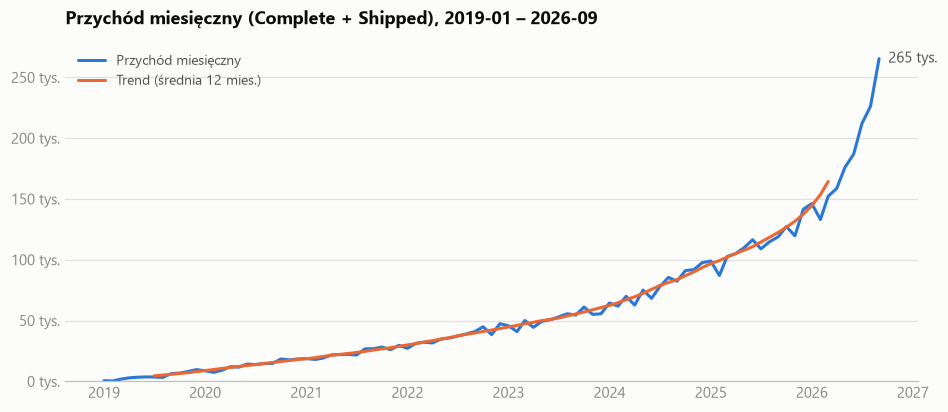

In [9]:
# Chart: monthly revenue with trend

x = monthly.index.to_timestamp()

fig, ax = plt.subplots()
ax.plot(x, monthly["revenue"], color=COLORS["series_1"], label="Przychód miesięczny")
ax.plot(x, monthly["trend"], color=COLORS["series_2"], label="Trend (średnia 12 mies.)")

# Direct label on the last point only – the latest value is the headline
ax.annotate(f"{monthly['revenue'].iloc[-1] / 1000:,.0f} tys.".replace(",", " "),
            xy=(x[-1], monthly["revenue"].iloc[-1]), xytext=(-6, 6), textcoords="offset points",
            ha="right", va="bottom", color=COLORS["text_secondary"])

ax.set_title(f"Przychód miesięczny (Complete + Shipped), {monthly.index[0]} – {monthly.index[-1]}")
ax.yaxis.set_major_formatter(thousands)
ax.set_ylim(bottom=0)
legend_outside(ax)
plt.show()

## 2. Wzrost rok do roku

Rok 2026 nie jest pełny, więc porównujemy **ten sam okres w każdym roku (YTD)**:
styczeń – ostatni pełny miesiąc. Inaczej 2026 zawsze wyglądałby na spadek.

In [10]:
# Year-to-date comparison: same months in every year

last_full_month = (current_month - 1).month

ytd = (orders_v[orders_v["month"].dt.month <= last_full_month]
       .groupby("year")
       .agg(orders=("order_id", "count"),
            revenue=("revenue", "sum"),
            active_customers=("user_id", "nunique"))
       .assign(revenue_yoy_pct=lambda x: x["revenue"].pct_change() * 100,
               orders_yoy_pct=lambda x: x["orders"].pct_change() * 100))

print(f"Okres porównania: styczeń–{last_full_month:02d} każdego roku")
ytd.round(1)

Okres porównania: styczeń–09 każdego roku


,orders,revenue,active_customers,revenue_yoy_pct,orders_yoy_pct
year,,,,,
2019,565,25491.2,551,NaN,<NA>
2020,2229,106082.3,2117,316.2,294.5
2021,4164,196770.4,3913,85.5,86.8
2022,6532,309389.3,6109,57.2,56.9
2023,9488,443830.9,8847,43.5,45.3
2024,13608,647994.1,12525,46.0,43.4
2025,20092,962508.4,17953,48.5,47.6
2026,34769,1656914.5,28145,72.1,73.0


## 3. Skąd wzrost? Klienci nowi vs powracający

* Nowi użytkownicy przybywają w stałym tempie, ale każdy z nich może wracać – baza powracających się kumuluje.
* Jaki udział w przychodzie mają zamówienia klientów powracających i jak zmienia się w czasie?

In [11]:
# Revenue by year: new vs returning customers

(orders_v
 .pivot_table(index="year", columns="customer_type", values="revenue", aggfunc="sum")
 .assign(returning_share_pct=lambda x: x["returning"] / (x["new"] + x["returning"]) * 100)
 .round(1))

customer_type,new,returning,returning_share_pct
year,,,
2019,48620.9,1399.7,2.8
2020,143190.5,17321.9,10.8
2021,237668.3,42827.6,15.3
2022,351886.0,88153.3,20.0
2023,445151.4,170358.5,27.7
2024,632124.5,296454.8,31.9
2025,817409.6,533606.7,39.5
2026,889736.4,767178.1,46.3


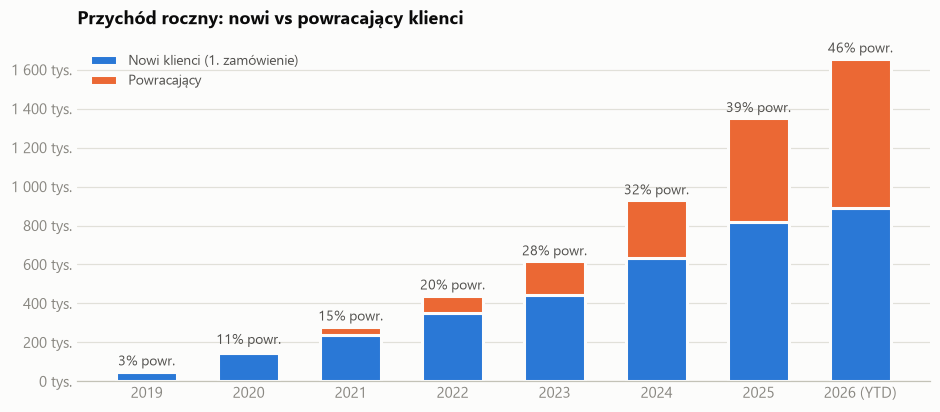

In [12]:
# Chart: revenue by year, stacked new + returning; label = share of returning customers

by_type = orders_v.pivot_table(index="year", columns="customer_type", values="revenue", aggfunc="sum")
returning_share = by_type["returning"] / by_type.sum(axis=1) * 100
labels = [f"{y} (YTD)" if y == current_month.year else str(y) for y in by_type.index]

fig, ax = plt.subplots()
ax.bar(labels, by_type["new"], width=0.6, color=COLORS["series_1"], label="Nowi klienci (1. zamówienie)",
       edgecolor=COLORS["surface"], linewidth=2)
ax.bar(labels, by_type["returning"], width=0.6, bottom=by_type["new"], color=COLORS["series_2"],
       label="Powracający", edgecolor=COLORS["surface"], linewidth=2)

for i, (total, share) in enumerate(zip(by_type.sum(axis=1), returning_share)):
    ax.annotate(f"{share:.0f}% powr.", xy=(i, total), xytext=(0, 4), textcoords="offset points",
                ha="center", color=COLORS["text_secondary"], fontsize=9)

ax.set_title("Przychód roczny: nowi vs powracający klienci")
ax.yaxis.set_major_formatter(thousands)
legend_outside(ax)
plt.show()

In [13]:
# Time from signup to first order – sanity check (orders before signup would be a data error)

first_order = orders.groupby("user_id")["created_at"].min()
signup = users.set_index("id")["created_at"].reindex(first_order.index)

days_to_first_order = (first_order - signup).dt.total_seconds() / 86400

print(f"Zamówienia przed rejestracją: {(days_to_first_order < 0).mean() * 100:.1f}% kupujących")
days_to_first_order.describe().round(1)

Zamówienia przed rejestracją: 0.0% kupujących


count    79748.0
mean       591.5
std        583.9
min          0.0
25%        127.0
50%        394.5
75%        895.8
max       2846.2
Name: created_at, dtype: float64

## 4. Sezonowość

* **Indeks sezonowy** = przychód w miesiącu / trend (średnia 12 mies. wokół tego miesiąca).
  1,10 oznacza miesiąc o 10% lepszy, niż wynikałoby z samego trendu. Uśredniamy po wszystkich latach.
* Dlaczego dzielimy przez trend, a nie przez średnią roku? Przy rosnącym biznesie grudzień jest „lepszy”
  od stycznia także dlatego, że biznes w ciągu roku urósł. Dzielenie przez trend usuwa ten efekt –
  zostaje czysta sezonowość.
* Dodatkowo: rozkład zamówień wg dnia tygodnia.

In [14]:
# Seasonal index by calendar month: revenue / trend, averaged over years

seasonal_ratio = (monthly["revenue"] / monthly["trend"]).dropna()

seasonal_index = seasonal_ratio.groupby(seasonal_ratio.index.month).agg(["mean", "count"])
seasonal_index.index = MONTHS_PL

print(f"Okres: {seasonal_ratio.index[0]} – {seasonal_ratio.index[-1]} (count = liczba lat w średniej)")
seasonal_index.round(3)

Okres: 2019-07 – 2026-03 (count = liczba lat w średniej)


,mean,count
sty,0.997,7
lut,0.897,7
mar,0.974,7
kwi,0.973,6
maj,0.998,6
cze,0.999,6
lip,0.949,7
sie,0.968,7
wrz,1.010,7
paź,1.064,7


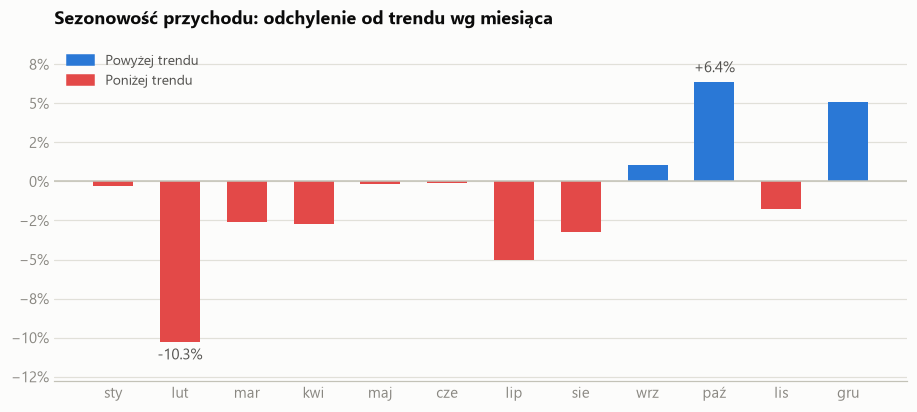

In [15]:
# Chart: seasonality – % above / below trend for each calendar month

deviation = (seasonal_index["mean"] - 1) * 100
bar_colors = np.where(deviation >= 0, COLORS["above"], COLORS["below"])

fig, ax = plt.subplots()
ax.bar(seasonal_index.index, deviation, width=0.6, color=bar_colors)
ax.axhline(0, color=COLORS["axis"], linewidth=1)

# Direct labels on the strongest and the weakest month only
for pos in [deviation.argmax(), deviation.argmin()]:
    value = deviation.iloc[pos]
    ax.annotate(f"{value:+.1f}%", xy=(pos, value), xytext=(0, 4 if value >= 0 else -4),
                textcoords="offset points", ha="center", va="bottom" if value >= 0 else "top",
                color=COLORS["text_secondary"])

ax.set_title("Sezonowość przychodu: odchylenie od trendu wg miesiąca")
ax.margins(y=0.15)                                          # room for the labels
ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
legend_outside(ax, handles=[plt.Rectangle((0, 0), 1, 1, color=COLORS["above"]),
                   plt.Rectangle((0, 0), 1, 1, color=COLORS["below"])],
               labels=["Powyżej trendu", "Poniżej trendu"])
plt.show()

In [16]:
# Orders by day of week (% of all orders)

day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
days_pl = ["pon", "wt", "śr", "czw", "pt", "sob", "nd"]

weekday_share = (orders_v["created_at"].dt.day_name()
                 .value_counts(normalize=True)
                 .reindex(day_order)
                 .mul(100))
weekday_share.index = days_pl

weekday_share.round(1)

pon    14.3
wt     14.2
śr     14.3
czw    14.3
pt     14.1
sob    14.3
nd     14.3
Name: proportion, dtype: float64

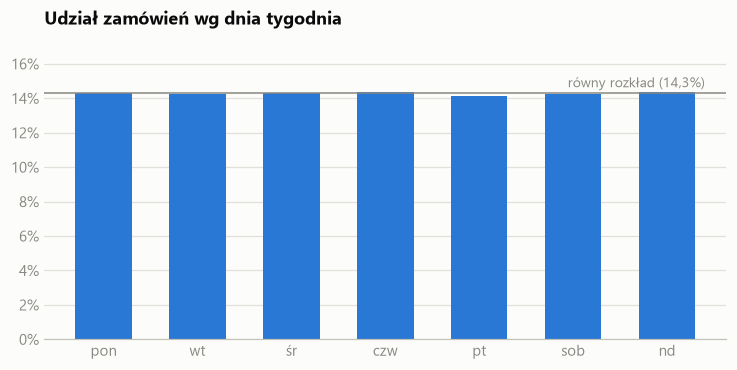

In [17]:
# Chart: orders by day of week – axis from 0, so a flat distribution looks flat

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(weekday_share.index, weekday_share, width=0.6, color=COLORS["series_1"])

ax.axhline(100 / 7, color=COLORS["muted"], linewidth=1)
ax.annotate("równy rozkład (14,3%)", xy=(6.4, 100 / 7), xytext=(0, 4), textcoords="offset points",
            ha="right", color=COLORS["muted"], fontsize=9)

ax.set_title("Udział zamówień wg dnia tygodnia")
ax.set_ylim(0, weekday_share.max() * 1.2)
ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
plt.show()

## 5. Statusy w czasie

* Czy odsetek anulowań i zwrotów jest stały, czy się zmienia? (temat A5)
* Uwaga: zamówienia z ostatnich miesięcy częściej mają status Processing / Shipped – jeszcze nie dotarły.

In [18]:
# Status mix by year (% of orders, each row = 100%)

pd.crosstab(orders_v["year"], orders_v["status"], normalize="index").mul(100).round(1)

status,Cancelled,Complete,Processing,Returned,Shipped
year,,,,,
2019,15.9,25.8,20.4,10.4,27.5
2020,14.1,25.0,20.4,10.0,30.6
2021,15.6,24.5,20.5,9.9,29.5
2022,15.1,25.3,19.5,10.1,30.0
2023,15.2,24.9,20.0,10.1,29.7
2024,15.1,25.3,19.8,10.1,29.8
2025,14.9,24.9,19.7,10.0,30.4
2026,14.9,25.5,20.0,10.0,29.7


In [19]:
# Status mix in the last 6 full months – recent orders are still "in progress"

recent = orders_v[orders_v["month"] >= current_month - 6]

pd.crosstab(recent["month"], recent["status"], normalize="index").mul(100).round(1)

status,Cancelled,Complete,Processing,Returned,Shipped
month,,,,,
2026-04,15.4,24.3,20.9,11.1,28.3
2026-05,14.9,25.8,19.8,10.0,29.4
2026-06,14.5,26.7,19.8,10.3,28.7
2026-07,14.3,25.3,19.1,10.5,30.8
2026-08,14.7,25.6,20.3,9.5,29.9
2026-09,14.7,25.4,19.9,9.4,30.6


## Wnioski (uzupełnij po uruchomieniu)

1.
2.
3.